# 05 - Mentor and Students' success
Using the past 8 academic years (AY 2018-19 to 2025-26). We want to explore how mentor influences a student's grades and withdraw rate.

In [95]:
import sys

sys.path.append("..")

import pandas as pd
from src.mongo_connect import get_db

db = get_db()
print(db.name)

nexus


## 1. Build the dataset
`students` is the main table, and each row is one enrollment.

Everything is matched to these rows:
- mentor name and netId: `students.mentor`
- final grade: `students.finalGrade` -> `finalgrades._id`
- withdraw: `students.status`

### 1.1 Load enrollments & Get mentor
The window is set on `term`: `120188` (Fall 2018) to `120267` (AY 2025-26).

In [96]:
df_students = pd.DataFrame(list(db.students.find(
    {"term": {"$gte": 120188, "$lte": 120267}},
    {"netId": 1, "term": 1, "course": 1, "status": 1, "finalGrade": 1, "mentor": 1, "isAdult": 1, "isPartner": 1},
)))
df_students["term"] = df_students["term"].astype(int)
df_students["course"] = df_students["course"].astype(int)

def term_to_academic_year(term):
    code = str(term)
    year = int(code[1:5])
    start = year if code.endswith("8") else year - 1
    return f"{start}-{str(start + 1)[2:]}"

def get_mentor_name(mentor):
    name = mentor.get("name") or {}
    return f"{name.get('first', '')} {name.get('last', '')}".strip() or None

df_students["academic_year"] = df_students["term"].map(term_to_academic_year)
df_students["mentor_name"] = df_students["mentor"].map(get_mentor_name)
df_students["mentor_netId"] = df_students["mentor"].map(lambda mentor: mentor.get("netId") or None)

print("rows:", len(df_students))
print("missing mentor name:", df_students["mentor_name"].isna().sum())
print("missing mentor netId:", df_students["mentor_netId"].isna().sum())

rows: 18198
missing mentor name: 10939
missing mentor netId: 10939


### 1.2 Match finagrades
`students.finalGrade` is an ObjectId pointing to `finalgrades._id`. The grade letter is mapped to `gpa` the same way as notebooks 02 and 04, so `W` and `Abs` have no GPA.

In [97]:
finalgrade_ids = df_students["finalGrade"].dropna().tolist()
df_finalgrades = pd.DataFrame(list(db.finalgrades.find({"_id": {"$in": finalgrade_ids}}, {"grade": 1})))
df_finalgrades = df_finalgrades.rename(columns={"_id": "finalGrade", "grade": "finalGradeLetter"})

rows_before = len(df_students)
df_students = df_students.merge(df_finalgrades, on="finalGrade", how="left")
assert len(df_students) == rows_before  # the merge must keep one row per enrollment

GRADE_TO_GPA = {
    "A+": 4.0, "A": 4.0, "A-": 3.7,
    "B+": 3.3, "B": 3.0, "B-": 2.7,
    "C+": 2.3, "C": 2.0, "C-": 1.7,
    "D+": 1.3, "D": 1.0, "D-": 0.7,
    "F": 0.0,
}
df_students["gpa"] = df_students["finalGradeLetter"].map(GRADE_TO_GPA)

print("rows with a finalGrade pointer:", df_students["finalGrade"].notna().sum())
print("pointers not found in finalgrades:", (df_students["finalGrade"].notna() & df_students["finalGradeLetter"].isna()).sum())
df_students["finalGradeLetter"].value_counts(dropna=False)

rows with a finalGrade pointer: 9307
pointers not found in finalgrades: 0


finalGradeLetter
NaN    8891
A      2704
A+     1432
A-     1328
B       924
F       690
B+      672
B-      405
C       374
C+      247
C-      175
D       122
W       110
D+       66
D-       54
Abs       4
Name: count, dtype: int64

### 1.3 Mark withdrawals from `status`
Same definition as notebook 04:
- `True`: `Withdrawn` or `Withdrawing`
- `False`: `Completed`
- `<NA>`: `Active`, because the outcome isn't known yet

In [98]:
df_students["withdrawn"] = df_students["status"].isin(["Withdrawn", "Withdrawing"]).astype("boolean")
df_students.loc[df_students["status"] == "Active", "withdrawn"] = pd.NA

pd.crosstab(df_students["status"], df_students["withdrawn"].astype("string").fillna("<NA>"))

withdrawn,<NA>,False,True
status,,,
Active,373,0,0
Completed,0,10876,0
Withdrawing,0,0,131
Withdrawn,0,0,6818


### 1.4 Final table
One row = one enrollment.

In [99]:
df_mentor_students = df_students.rename(columns={"_id": "enrollment_id", "netId": "student_netId"})[[
    "enrollment_id", "student_netId", "academic_year", "term", "course",
    "mentor_name", "mentor_netId",
    "finalGrade", "finalGradeLetter", "gpa",
    "status", "withdrawn",
    "isAdult", "isPartner",
]]

assert df_mentor_students["enrollment_id"].is_unique

print(df_mentor_students.shape)
df_mentor_students.drop(columns=["enrollment_id", "student_netId", "finalGrade"]).head()

(18198, 14)


,academic_year,term,course,mentor_name,mentor_netId,finalGradeLetter,gpa,status,withdrawn,isAdult,isPartner
0,2019-20,120205,241,NaN,NaN,NaN,NaN,Withdrawn,True,True,False
1,2018-19,120197,241,Shreyas Gandlur,gandlur2,A-,3.7,Completed,False,False,False
2,2018-19,120197,241,Harry Wu,hwu57,A,4.0,Completed,False,False,False
3,2018-19,120197,124,Noah Chartoff,chartff2,C,2.0,Completed,False,True,False
4,2018-19,120197,415,Becky Song,rwsong2,B,3.0,Completed,False,False,False


## 2. Compare mentors

In [100]:
import numpy as np
import matplotlib.pyplot as plt

# white background
plt.style.use("default")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

MIN_N = 15

BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#0b0b0b"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

def style_axes(ax, xlabel, title, grid="x"):
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def plot_mentor_bars(table, value_col, n_col, reference, xlabel, title, xlim):
    t = table.sort_values(value_col)
    fig, ax = plt.subplots(figsize=(10, max(4, 0.24 * len(t) + 1.5)))
    ax.barh(range(len(t)), t[value_col], height=0.7, color=BLUE)
    ax.set_yticks(range(len(t)), [f"{m} (n={n})" for m, n in zip(t["mentor_label"], t[n_col])], fontsize=8)
    ax.set_ylim(-0.7, len(t) - 0.3)
    ax.set_xlim(*xlim)
    ax.axvline(reference, color=INK, linewidth=1)
    style_axes(ax, xlabel, f"{title}\nblack line = all mentors, {reference:.2f}")
    plt.tight_layout()
    plt.show()

### 2.1 Keep enrollments with a mentor
Only 7,259 of the 18,198 rows have a mentor, so all results below describe those rows. Summer rows are almost all left out: only 3 of 6,972 have a mentor.

In [109]:
df_m = df_mentor_students[df_mentor_students["mentor_netId"].notna()].copy()
df_m["mentor_netId"] = df_m["mentor_netId"].str.strip().str.lower()
df_m["isPartner"] = df_m["isPartner"].astype(bool)

# one netId has two spellings of a name, so use each netId's most common name
labels = df_m.groupby("mentor_netId")["mentor_name"].agg(lambda names: names.mode().iat[0])
df_m["mentor_label"] = df_m["mentor_netId"].map(labels)

print("rows:", len(df_m))
print("mentors:", df_m["mentor_netId"].nunique())

rows: 7259
mentors: 92


### 2.2 One row per mentor

In [102]:
graded = df_m[df_m["gpa"].notna()]
known = df_m[df_m["withdrawn"].notna()].copy()
known["withdrawn"] = known["withdrawn"].astype(bool)

mentor_table = (
    graded.groupby("mentor_netId")["gpa"].agg(n_graded="count", avg_gpa="mean", median_gpa="median")
    .join(known.groupby("mentor_netId")["withdrawn"].agg(n_known="count", n_withdrawn="sum"), how="outer")
    .join(df_m.groupby("mentor_netId").agg(
        mentor_label=("mentor_label", "first"),
        n_courses=("course", "nunique"),
        partner_share=("isPartner", lambda s: s.mean() * 100),
    ))
)
mentor_table[["n_graded", "n_known", "n_withdrawn"]] = mentor_table[["n_graded", "n_known", "n_withdrawn"]].fillna(0).astype(int)
mentor_table["withdraw_rate"] = mentor_table["n_withdrawn"] / mentor_table["n_known"] * 100

overall_gpa = graded["gpa"].mean()
overall_wd = known["withdrawn"].mean() * 100
print(f"all enrollments with a mentor: average GPA {overall_gpa:.2f}, withdraw rate {overall_wd:.1f}%")
print("mentors:", len(mentor_table))
print(f"  with at least {MIN_N} graded students:", (mentor_table["n_graded"] >= MIN_N).sum())
print(f"  with at least {MIN_N} students with a known outcome:", (mentor_table["n_known"] >= MIN_N).sum())

with pd.option_context("display.max_rows", None):
    display(mentor_table[["mentor_label", "n_courses", "n_graded", "avg_gpa", "median_gpa", "n_known",
                          "withdraw_rate", "partner_share"]].sort_values("avg_gpa", ascending=False).round(2))

all enrollments with a mentor: average GPA 3.00, withdraw rate 43.6%
mentors: 92
  with at least 15 graded students: 28
  with at least 15 students with a known outcome: 48


,mentor_label,n_courses,n_graded,avg_gpa,median_gpa,n_known,withdraw_rate,partner_share
mentor_netId,,,,,,,,
afei3,Andrew Fei,1,3,4.00,4.00,4,25.00,0.00
bharba2,Brett Harbaugh,1,1,4.00,4.00,4,75.00,0.00
pps2,Priyam Shah,1,1,4.00,4.00,2,50.00,0.00
ppadhye2,Prathamesh Padhye,1,1,4.00,4.00,1,0.00,0.00
nim4,Ilya Shahriz,1,1,4.00,4.00,2,50.00,0.00
jnicker2,Jaclyn Nickerson,1,4,4.00,4.00,12,66.67,0.00
eugenep2,Jane Park,1,2,4.00,4.00,17,88.24,0.00
yugm2,Yug Mittal,1,6,4.00,4.00,13,53.85,0.00
fireman,Ellen Fireman,1,7,3.96,4.00,27,74.07,0.00


### 2.3 Average GPA by mentor
Only graded students count toward GPA. Mentors with fewer than `MIN_N` graded students are left out.

mentors shown: 28 of 92


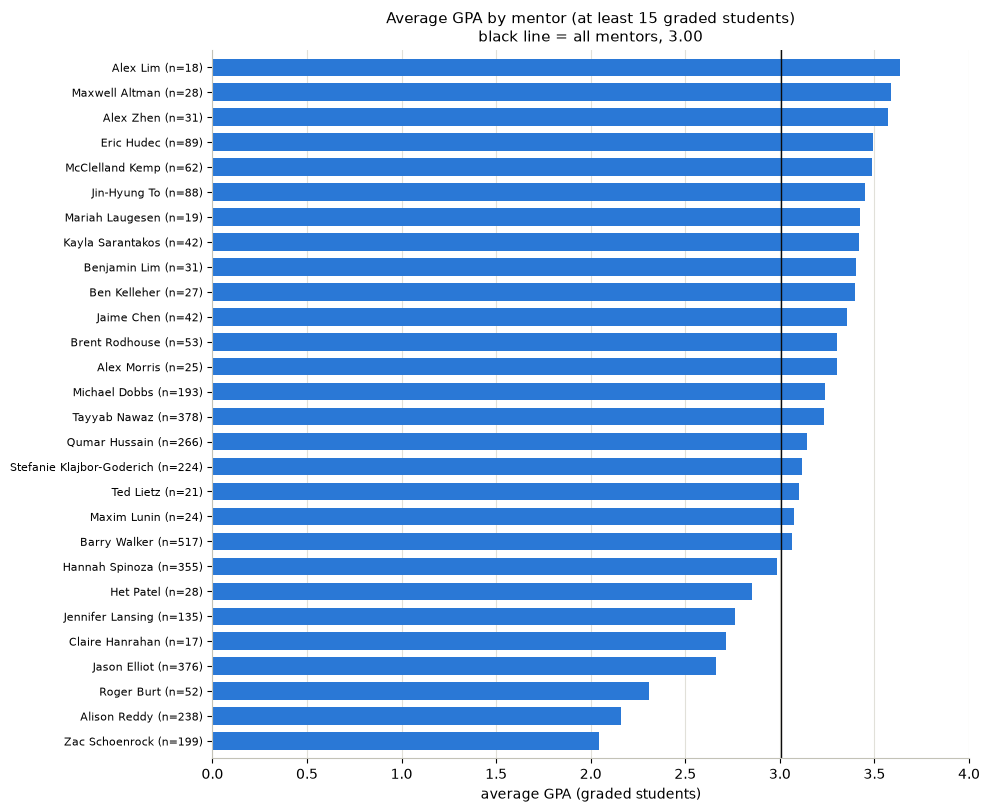

In [112]:
mentors_gpa = mentor_table[mentor_table["n_graded"] >= MIN_N]
print(f"mentors shown: {len(mentors_gpa)} of {len(mentor_table)}")

plot_mentor_bars(
    mentors_gpa, "avg_gpa", "n_graded", overall_gpa,
    "average GPA (graded students)",
    f"Average GPA by mentor (at least {MIN_N} graded students)",
    (0, 4),
)

### 2.4 Withdraw rate by mentor
`withdraw rate = withdrawn / students with a known outcome`, so `Active` students are left out. Mentors with fewer than `MIN_N` such students are left out.

mentors shown: 48 of 92


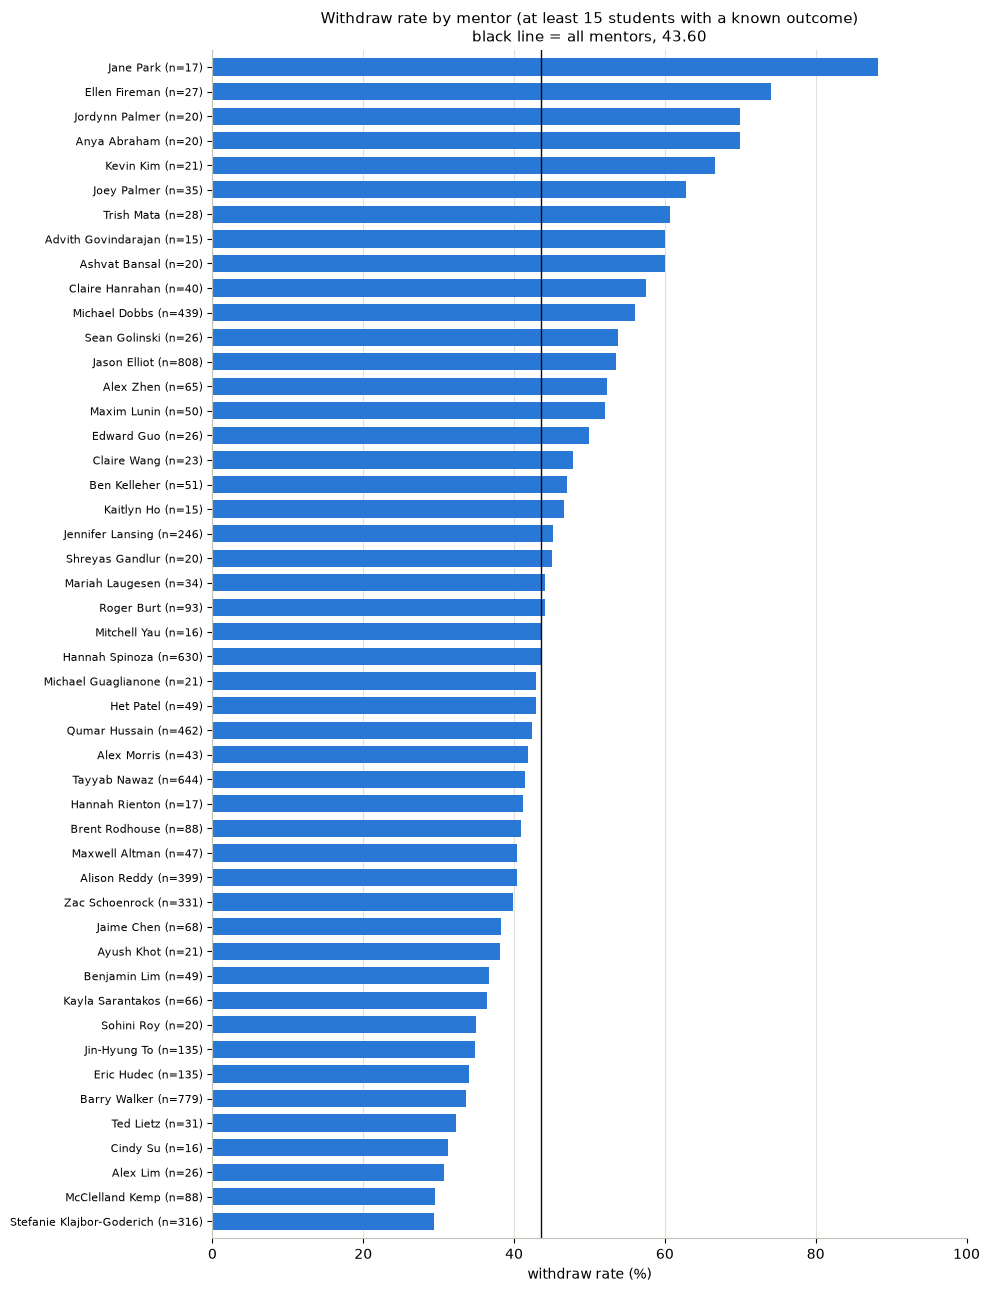

In [113]:
mentors_wd = mentor_table[mentor_table["n_known"] >= MIN_N]
print(f"mentors shown: {len(mentors_wd)} of {len(mentor_table)}")

plot_mentor_bars(
    mentors_wd, "withdraw_rate", "n_known", overall_wd,
    "withdraw rate (%)",
    f"Withdraw rate by mentor (at least {MIN_N} students with a known outcome)",
    (0, 100),
)

### 2.5 Average GPA vs withdraw rate
Each dot is one mentor with at least `MIN_N` graded students and `MIN_N` students with a known outcome. The line is a straight-line fit through the dots.

mentors: 28
fit: GPA = 3.71 -0.0142 x withdraw rate (%)
correlation: -0.26


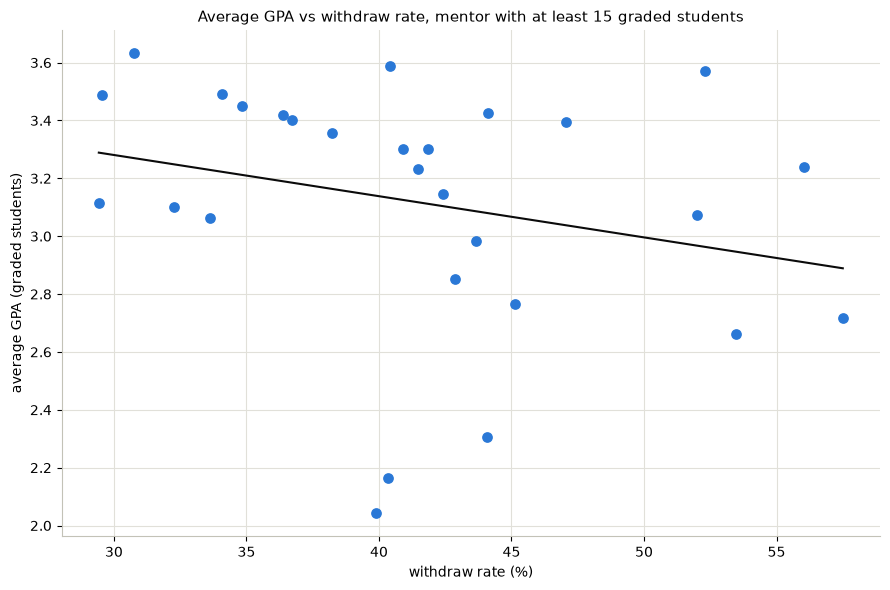

In [118]:
mentors_both = mentor_table[(mentor_table["n_graded"] >= MIN_N) & (mentor_table["n_known"] >= MIN_N)]
x = mentors_both["withdraw_rate"].to_numpy()
y = mentors_both["avg_gpa"].to_numpy()

slope, intercept = np.polyfit(x, y, 1)
correlation = np.corrcoef(x, y)[0, 1]
print(f"mentors: {len(mentors_both)}")
print(f"fit: GPA = {intercept:.2f} {slope:+.4f} x withdraw rate (%)")
print(f"correlation: {correlation:+.2f}")

line_x = np.array([x.min(), x.max()])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x, y, s=45, color=BLUE, zorder=3)
ax.plot(line_x, intercept + slope * line_x, color=INK, linewidth=1.5, zorder=2)
style_axes(ax, "withdraw rate (%)", "Average GPA vs withdraw rate, mentor with at least 15 graded students", grid="both")
ax.set_ylabel("average GPA (graded students)")
plt.tight_layout()
plt.show()

## 3. Within the same course, do students of different mentors have different outcomes?
### 3.1 Which courses does each mentor teach?

In [106]:
mentor_course_counts = df_m.groupby(["mentor_netId", "mentor_label", "course"]).size().rename("n").reset_index()

mentor_courses = mentor_course_counts.groupby(["mentor_netId", "mentor_label"]).agg(
    n_courses=("course", "nunique"),
    n_enrollments=("n", "sum"),
    courses=("course", lambda courses: ", ".join(str(c) for c in sorted(courses))),
).sort_values("n_enrollments", ascending=False)

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(mentor_courses)

,,n_courses,n_enrollments,courses
mentor_netId,mentor_label,,,
jelliot2,Jason Elliot,4,883,"285, 286, 417, 447"
bjwalker,Barry Walker,6,821,"241, 292, 415, 444, 446, 481"
tnawaz2,Tayyab Nawaz,8,733,"257, 285, 286, 441, 442, 448, 461, 490"
hkolb2,Hannah Spinoza,7,683,"241, 314, 415, 416, 423, 444, 481"
qhussain,Qumar Hussain,2,494,"441, 442"
micdobbs,Michael Dobbs,3,439,"220, 231, 234"
ared,Alison Reddy,3,399,"112, 114, 115"
klajbor2,Stefanie Klajbor-Goderich,1,365,241
schoenro,Zac Schoenrock,9,331,"220, 231, 234, 241, 285, 286, 292, 415, 461"


### 3.2 Lowest vs highest mentor within the same course
For each course, compare the mentor with the lowest average to the mentor with the highest. A bigger gap means a bigger difference between mentors in that course.

Only mentors with at least `MIN_N` students in that course count, and a course needs at least 2 such mentors. The gaps come from raw averages, so they don't account for academic year, student type or chance.

,n_mentors,lowest,highest,gap
course,,,,
220,2,0.90,3.38,2.48
285,5,1.37,3.59,2.22
241,8,1.96,3.57,1.61
415,6,2.16,3.63,1.47
286,2,2.09,3.40,1.31
231,4,2.14,3.25,1.11
416,2,3.01,3.62,0.62
461,3,2.90,3.49,0.58
423,2,2.15,2.54,0.39


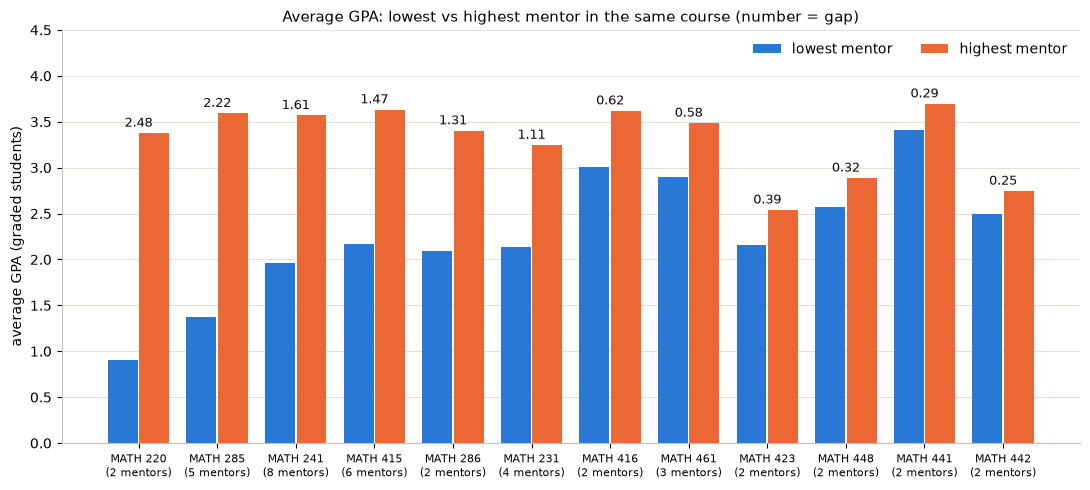

,n_mentors,lowest,highest,gap
course,,,,
285,7,16.1,66.7,50.5
220,5,39.5,88.2,48.8
241,17,27.3,70.0,42.7
231,7,21.1,60.7,39.7
286,4,14.3,38.9,24.6
415,9,30.8,53.8,23.1
423,2,32.1,54.2,22.0
448,2,37.9,52.2,14.2
461,3,29.5,38.2,8.6


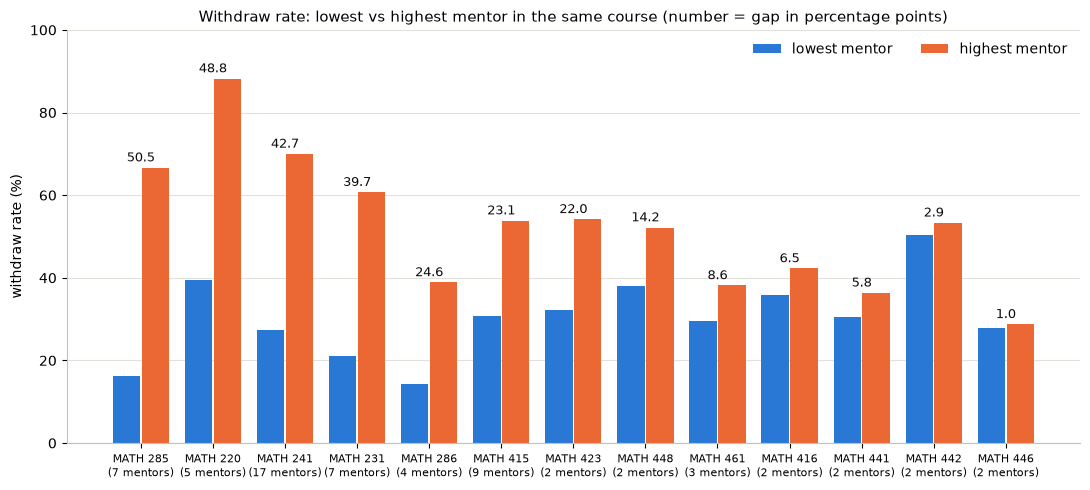

In [107]:
def course_gaps(value_col, scale=1):
    """Lowest and highest mentor average per course, sorted by the gap between them."""
    d = df_m[df_m[value_col].notna()].copy()
    d[value_col] = d[value_col].astype(float) * scale
    per_mentor = d.groupby(["course", "mentor_netId"])[value_col].agg(n="count", average="mean").reset_index()
    per_mentor = per_mentor[per_mentor["n"] >= MIN_N]

    gaps = per_mentor.groupby("course")["average"].agg(n_mentors="count", lowest="min", highest="max")
    gaps = gaps[gaps["n_mentors"] >= 2]
    gaps["gap"] = gaps["highest"] - gaps["lowest"]
    return gaps.sort_values("gap", ascending=False)


def plot_course_gaps(gaps, ylabel, title, ymax, gap_format):
    fig, ax = plt.subplots(figsize=(11, 5))
    positions = np.arange(len(gaps))
    ax.bar(positions - 0.2, gaps["lowest"], width=0.38, color=BLUE, label="lowest mentor")
    ax.bar(positions + 0.2, gaps["highest"], width=0.38, color=ORANGE, label="highest mentor")

    for position, highest, gap in zip(positions, gaps["highest"], gaps["gap"]):
        ax.text(position, highest + ymax * 0.015, gap_format.format(gap), ha="center", fontsize=9, color=INK)

    ax.set_xticks(positions, [f"MATH {c}\n({m} mentors)" for c, m in zip(gaps.index, gaps["n_mentors"])], fontsize=8)
    ax.set_ylim(0, ymax)
    ax.set_ylabel(ylabel)
    style_axes(ax, "", title, grid="y")
    ax.legend(frameon=False, loc="upper right", ncols=2)
    plt.tight_layout()
    plt.show()


gpa_gaps = course_gaps("gpa")
wd_gaps = course_gaps("withdrawn", scale=100)

display(gpa_gaps.round(2))
plot_course_gaps(gpa_gaps, "average GPA (graded students)",
                 "Average GPA: lowest vs highest mentor in the same course (number = gap)", 4.5, "{:.2f}")

display(wd_gaps.round(1))
plot_course_gaps(wd_gaps, "withdraw rate (%)",
                 "Withdraw rate: lowest vs highest mentor in the same course (number = gap in percentage points)",
                 min(100, wd_gaps["highest"].max() + 15), "{:.1f}")

### 3.3 Zoom in: MATH 241 letter grades by mentor
Each bar is one mentor and shows what share of their graded MATH 241 students got each letter grade. Plus and minus grades are grouped, so `A` includes `A+`, `A` and `A-`. `W` and `Abs` are left out, and so are mentors with fewer than `MIN_N` graded students in the course. Bars are sorted by share of `A`.

grade_band,A,B,C,D,F,n
mentor_label,,,,,,
Alex Zhen,71.0,16.1,12.9,0.0,0.0,31
Ben Kelleher,66.7,18.5,7.4,3.7,3.7,27
Jaime Chen,64.3,16.7,16.7,2.4,0.0,42
Eric Hudec,62.5,28.1,6.2,0.0,3.1,32
Stefanie Klajbor-Goderich,62.1,17.4,5.8,1.3,13.4,224
Maxim Lunin,50.0,33.3,5.6,5.6,5.6,18
Ted Lietz,47.1,35.3,0.0,11.8,5.9,17
Zac Schoenrock,37.0,13.0,5.6,1.9,42.6,54


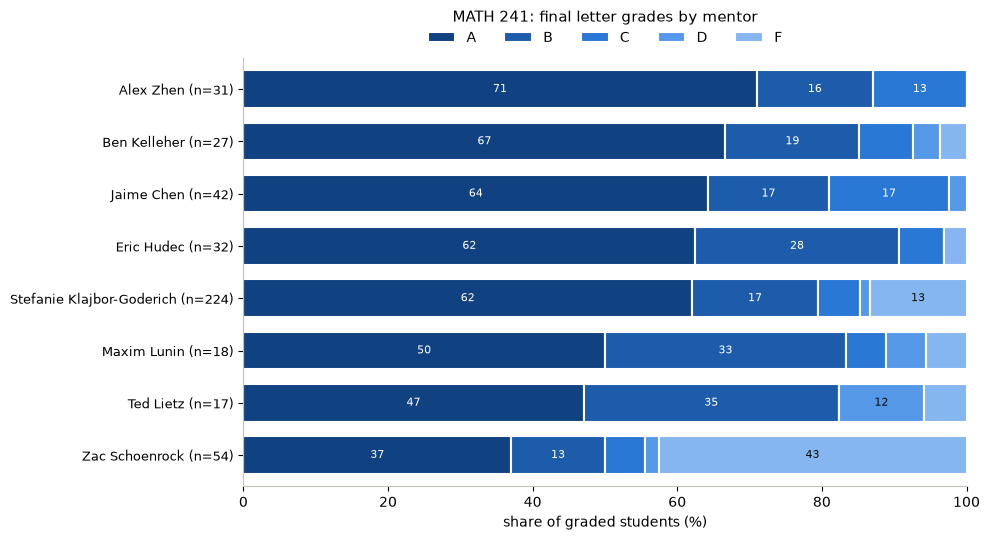

In [119]:
GRADE_BANDS = ["A", "B", "C", "D", "F"]
BAND_COLORS = ["#104281", "#1c5cab", "#2a78d6", "#5598e7", "#86b6ef"]  # one hue, dark = higher grade
BAND_TEXT = ["white", "white", "white", INK, INK]

math241 = df_m[(df_m["course"] == 241) & df_m["gpa"].notna()].copy()
math241["grade_band"] = math241["finalGradeLetter"].str[0]

n_241 = math241.groupby("mentor_label").size()
math241 = math241[math241["mentor_label"].map(n_241) >= MIN_N]

grade_mix = (
    pd.crosstab(math241["mentor_label"], math241["grade_band"], normalize="index")
    .mul(100)
    .reindex(columns=GRADE_BANDS, fill_value=0)
    .sort_values("A")
)

display(grade_mix.assign(n=n_241).sort_values("A", ascending=False).round(1))

fig, ax = plt.subplots(figsize=(10, max(3.5, 0.5 * len(grade_mix) + 1.5)))
left = np.zeros(len(grade_mix))
for band, color, text_color in zip(GRADE_BANDS, BAND_COLORS, BAND_TEXT):
    values = grade_mix[band].to_numpy()
    ax.barh(range(len(grade_mix)), values, left=left, height=0.72, color=color,
            edgecolor="white", linewidth=1.5, label=band)
    for row, (start, value) in enumerate(zip(left, values)):
        if value >= 8:  # only label segments wide enough to hold the number
            ax.text(start + value / 2, row, f"{value:.0f}", ha="center", va="center", fontsize=8, color=text_color)
    left += values

ax.set_yticks(range(len(grade_mix)), [f"{m} (n={n_241[m]})" for m in grade_mix.index], fontsize=9)
ax.set_ylim(-0.6, len(grade_mix) - 0.4)
ax.set_xlim(0, 100)
style_axes(ax, "share of graded students (%)", "MATH 241: final letter grades by mentor")
ax.title.set_position((0.5, 1.0))
ax.set_title(ax.get_title(), fontsize=11, pad=26)
ax.grid(False)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=5)
plt.tight_layout()
plt.show()